# Data without replicates

With a single sample there are no replicates to compare conditions against, but diffsvg can still describe how genes change with the distance to an anchor. `tl.fit_profiles` fits one curve per gene, and `tl.one_vs_rest` compares the curve of one gene with the curves of all others. The example is one section of a control organoid from Legnini et al., where a small domain of cells expresses SHH. The anchor is the top 1% of SHH expression in that section, and the gene to compare is GLI1, a direct SHH target.

In [1]:
# One BLAS thread per process; set before numpy is imported.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

N_WORKERS = int(os.environ.get("DIFFSVG_WORKERS", 4))
LAYER = "log1p_norm"
PROBE = "GLI1"
MIN_CELLS = 10  # genes detected in fewer cells have no curve to compare

## 1. Section and anchor

In [2]:
adata = dvg.datasets.legnini23()
adata = adata[adata.obs["sample"] == "slide4_B2-3"].copy()  # a control organoid

shh = sc.get.obs_df(adata, "SHH", layer=LAYER)["SHH"].to_numpy()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

detected = np.asarray((adata.layers[LAYER] > 0).sum(axis=0)).ravel()
GENES = list(adata.var_names[detected >= MIN_CELLS])
print(f"{adata.n_obs} cells, {len(GENES)} of {adata.n_vars} genes detected in at least {MIN_CELLS} cells")

sq.tl.var_by_distance(adata, cluster_key="SHH+", groups="True")

1643 cells, 81 of 88 genes detected in at least 10 cells


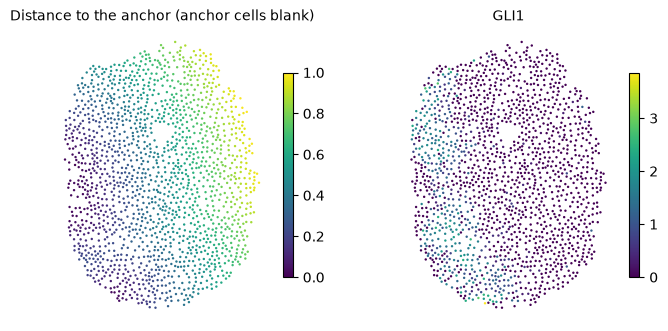

In [3]:
def gene_values(gene):
    return sc.get.obs_df(adata, gene, layer=LAYER)[gene].to_numpy()


def tissue_maps(panels, ncols=4):
    """One map per entry of `panels`, {title: values}, on the tissue's own coordinates."""
    ncols = min(ncols, len(panels))
    nrows = (len(panels) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.2 * nrows), squeeze=False, constrained_layout=True)
    for ax in axes.ravel()[len(panels) :]:
        ax.set_visible(False)
    xy = adata.obsm["spatial"]
    for ax, (title, values) in zip(axes.ravel(), panels.items(), strict=False):
        order = np.argsort(np.nan_to_num(values))  # high values on top
        points = ax.scatter(*xy[order].T, c=values[order], cmap="viridis", s=3, linewidth=0)
        ax.set_title(title, fontsize=10)
        ax.set_aspect("equal")
        ax.set_axis_off()
        fig.colorbar(points, ax=ax, shrink=0.7)


distance = adata.obsm["design_matrix"]["True"].to_numpy()
tissue_maps({"Distance to the anchor (anchor cells blank)": distance, PROBE: gene_values(PROBE)})

## 2. One curve per gene

`bin_obs(condition=None)` averages each gene in bins along the distance, and `fit_profiles` fits one curve per gene.

In [4]:
dvg.pp.bin_obs(adata, anchor="True", condition=None, genes=GENES, layer=LAYER, n_bins=50)
dvg.tl.fit_profiles(adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS)
profiles = adata.varm["dsvg_profiles_mean"].loc[GENES]

## 3. One gene against the rest

`one_vs_rest` tests, for every other gene, whether its curve differs in shape from the curve of the probe gene, beyond a difference in level. `delta` is the signed area between the two curves (negative when the probe is lower), and `T` their mean squared gap. `tau` defaults to 0.1 log units, so smaller differences in shape don't count.

The units of this test are the cells of one section, so its p-values show that a difference is measured precisely, not that it would repeat in another sample. With thousands of cells nearly every gene passes, so read the result as a ranking by `T` or `delta`. `shape_diff` is in log-expression units and is larger for highly expressed genes.

In [5]:
ovr = dvg.tl.one_vs_rest(adata, PROBE)
print(f"{(ovr['parallel_pval_adj'] < 0.05).sum()} of {len(ovr)} genes differ in shape from {PROBE} (BH < 0.05)")
ovr.sort_values("parallel_stat", ascending=False).head(10)

80 of 80 genes differ in shape from GLI1 (BH < 0.05)


,delta,T,shape_diff,parallel_stat,parallel_pval,parallel_pval_adj
PAX7,-1.218819,2.570843,3.678362,1772.016880,0.000000e+00,0.000000e+00
MSX2,0.037404,0.311396,1.946210,1386.623030,2.392522e-265,6.380059e-264
JUN,-1.179019,2.175786,3.133897,1357.694526,2.283971e-271,9.135885e-270
Circ.RMST,-2.575005,7.378205,3.160469,1333.818336,1.708954e-264,3.417908e-263
CDR1,0.307811,0.255387,1.407776,1280.577281,8.518712e-235,1.135828e-233
AQP4,0.302548,0.253861,1.414990,1279.760734,7.064501e-235,1.130320e-233
TUBB1,0.305043,0.255579,1.416088,1274.324487,8.456172e-234,9.664196e-233
EYA4,0.306721,0.253714,1.402720,1267.946315,2.529599e-232,2.491491e-231
HOPX,0.301942,0.251530,1.406558,1266.512217,2.802927e-232,2.491491e-231
LUM,0.301720,0.250813,1.404402,1256.173959,2.246334e-230,1.797067e-229


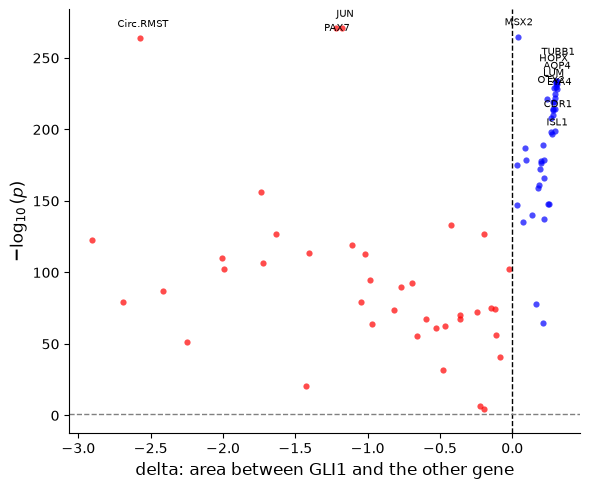

In [6]:
dvg.pl.plot_volcano(ovr, x="delta", pvalue="parallel_pval", pvalue_adj="parallel_pval_adj", n_label=12, figsize=(6, 5))
plt.gca().set_xlabel(f"delta: area between {PROBE} and the other gene");

All genes differ from GLI1, as expected with cells as units. The largest differences in shape are PAX7 and MSX2, dorsal genes that SHH represses, and the immediate-early gene JUN.

The probe's curve next to the genes closest to it and farthest from it. The left panel keeps the levels, as `T` does, and the right panel removes each gene's mean, which shows the genes with the most similar shape.

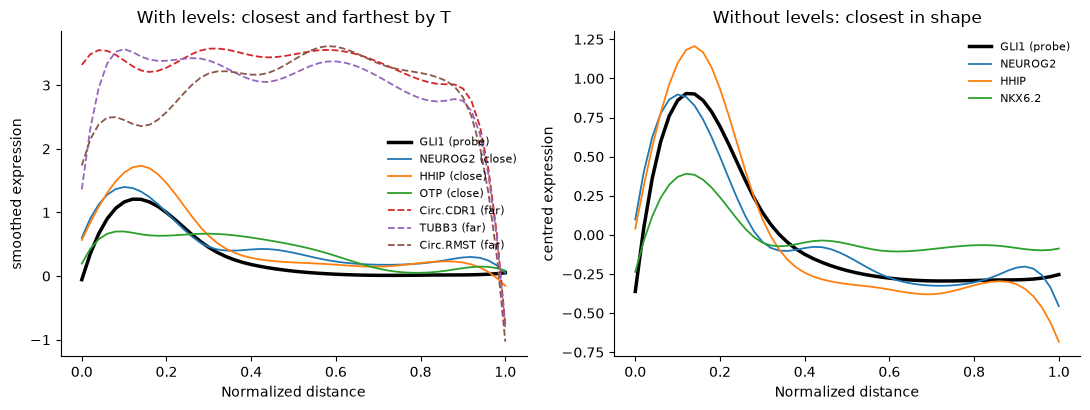

In [7]:
x = profiles.columns.to_numpy(dtype=float)
closest, farthest = list(ovr["T"].nsmallest(3).index), list(ovr["T"].nlargest(3).index)
centred = profiles.sub(profiles.mean(axis=1), axis=0)
gap_shape = ((centred.drop(index=PROBE) - centred.loc[PROBE]) ** 2).mean(axis=1)
same_shape = list(gap_shape.nsmallest(3).index)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(x, profiles.loc[PROBE], color="black", lw=2.5, label=f"{PROBE} (probe)")
for gene in closest:
    axes[0].plot(x, profiles.loc[gene], lw=1.3, ls="-", label=f"{gene} (close)")
for gene in farthest:
    axes[0].plot(x, profiles.loc[gene], lw=1.3, ls="--", label=f"{gene} (far)")
axes[0].set(xlabel="Normalized distance", ylabel="smoothed expression", title="With levels: closest and farthest by T")
axes[1].plot(x, centred.loc[PROBE], color="black", lw=2.5, label=f"{PROBE} (probe)")
for gene in same_shape:
    axes[1].plot(x, centred.loc[gene], lw=1.3, label=gene)
axes[1].set(xlabel="Normalized distance", ylabel="centred expression", title="Without levels: closest in shape")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout();

GLI1 peaks next to the SHH cells and falls within the first third of the distance. HHIP, another SHH target, and NEUROG2 have the same shape. The genes farthest by `T` are highly expressed genes that differ from GLI1 mostly in level.

## How this relates to Moran's I

Moran's I and Geary's C (`squidpy.gr.spatial_autocorr`) ask whether neighbouring cells have similar expression, whatever the pattern, and need no anchor. diffsvg asks how expression changes with the distance to one anchor. A gene that forms patches unrelated to the anchor is spatially variable for Moran's I and flat for diffsvg, so use Moran's I to find spatially variable genes in general and diffsvg to describe and compare their relation to a structure you choose.